# Knowing When to Defer: An Ordinal Evidential Involution–Attention Network for Calibrated Knee Osteoarthritis Grading

## 01 — Cohorts and data characteristics



### Setup

Mount Drive so the preprocessed cache survives a disconnect.

In [ ]:
# --- Colab bootstrap: run this first in every notebook ---------------------
import os, sys, glob, shutil

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = True        # True = results survive a disconnect. False = faster, but temporary.

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = "/content/drive/MyDrive/EvIA_Knee"
elif IN_COLAB:
    PROJECT = "/content/EvIA_Knee"
else:
    PROJECT = os.path.abspath(".")

os.makedirs(PROJECT, exist_ok=True)
sys.path.insert(0, PROJECT)          # so `import evia_knee` finds the module written by 00
CACHE = os.path.join(PROJECT, "cache")
print("project:", PROJECT)

Mounted at /content/drive
project: /content/drive/MyDrive/EvIA_Knee


In [ ]:
import math
import numpy as np, pandas as pd
import tensorflow as tf
import scipy.ndimage as ndi
from scipy import stats
import matplotlib.pyplot as plt

import evia_knee as E
assert hasattr(E.Config(), "lr_schedule"), \
    "Old evia_knee.py loaded. Run 00_core, then Runtime > Restart session."
print("evia_knee:", E.__file__, "| lr schedule", E.Config().lr_schedule)
import evia_viz as V                 # figure style, written by notebook 00
V.use()                # found via PROJECT, added to sys.path by the bootstrap
from evia_knee import Config

CFG = Config(img_size=224, preprocess="clahe", out_dir=os.path.join(PROJECT, "results"))
os.makedirs(CFG.out_dir, exist_ok=True)
GRADES = E.GRADE_NAMES
rng = np.random.default_rng(0)
print("results ->", CFG.out_dir)

evia_knee: /content/drive/MyDrive/EvIA_Knee/evia_knee.py | lr schedule cosine
results -> /content/drive/MyDrive/EvIA_Knee/results


### 0. Get the data

**Kaggle notebooks** — add the dataset via *+ Add Input*; it lands under `/kaggle/input` and is
found automatically. Skip the next cell.

**Colab / local** — run the next cell once. You need a Kaggle API token
(*Kaggle → Settings → API → Create New Token*). This is a plain dataset, so there are **no
competition rules to accept**.

Images come from the Mendeley *Knee Osteoarthritis Severity Grading Dataset*. Mirrors move, so
the helper tries several; if all fail, download it manually and set
`E.DATA_ROOTS["knee"] = "/content/knee"`.

In [ ]:
if IN_COLAB and not os.path.isdir("/content/knee"):
    # 1. Kaggle CLI
    !pip -q install kaggle

    # 2. credentials: upload kaggle.json when prompted
    from google.colab import files


    # 3. download + unzip
    E.download_kaggle("knee", "/content/knee")

# Data stays on the VM disk (fast). Only the small preprocessed cache goes to Drive.
# If your copy lives elsewhere, one line overrides all auto-discovery:
# E.DATA_ROOTS["knee"] = "/content/drive/MyDrive/knee"

root = E.find_dataset("knee")
print("knee data at:", root)
for d in sorted({os.path.dirname(p)
                 for p in glob.glob(root + "/**/*.png", recursive=True)}):
    print(f"  {os.path.basename(d):14s} {len(glob.glob(d + '/*.png')):5d} images")
print("\nKL1 vs KL2 is the boundary that decides definite OA, and the one "
      "readers disagree on most.")

kaggle datasets download -d shashwatwork/knee-osteoarthritis-dataset-with-severity -p /content/knee
unzipping knee-osteoarthritis-dataset-with-severity.zip
registered DATA_ROOTS['knee'] = /content/knee
knee data at: /content/knee
  0                604 images
  1                275 images
  2                403 images
  3                200 images
  4                 44 images
  0                639 images
  1                296 images
  2                447 images
  3                223 images
  4                 51 images
  0               2286 images
  1               1046 images
  2               1516 images
  3                757 images
  4                173 images
  0                328 images
  1                153 images
  2                212 images
  3                106 images
  4                 27 images

KL1 vs KL2 is the boundary that decides definite OA, and the one readers disagree on most.


### 1. Cohort composition

In [ ]:
ds = E.load_knee(cfg=CFG, seed=42)
# keep only knees that belong to a split: the mirror's auto_test folder (1,526 detector-cropped
# knees) is loaded by the folder scan but is not part of the study, so it must not enter any count
_idx0 = ds["idx"]
_keep = np.sort(np.concatenate([_idx0[k] for k in ("train", "val", "test")]))
_remap = -np.ones(len(ds["y"]), dtype=int); _remap[_keep] = np.arange(len(_keep))
print(f"  excluded (in no split, e.g. auto_test): {len(ds['y']) - len(_keep)} images")
ds = dict(ds, y=ds["y"][_keep], paths=np.asarray(ds["paths"])[_keep],
          idx={k: _remap[v] for k, v in _idx0.items()})
y, idx = ds["y"], ds["idx"]

# counts per grade per split -> Table 1 of the paper
tab = pd.DataFrame({s: np.bincount(y[i], minlength=5) for s, i in idx.items()}, index=GRADES)
tab["total"] = tab.sum(1)
tab["%"] = (100 * tab.total / tab.total.sum()).round(1)
print(f"{ds['name']} — images per grade")
print(tab.to_string())

n = len(y); cnt = np.bincount(y, minlength=5); thr = E.OA_THRESHOLD
print(f"\ntotal            {n}")
print(f"definite OA (>={thr}) {(y>=thr).sum()} ({(y>=thr).mean():.1%})  "
      f"[{E.OA_NAME}]")
print(f"largest class    {GRADES[cnt.argmax()]} ({cnt.max()/n:.1%})")
print(f"imbalance ratio  {cnt.max()/max(cnt.min(),1):.1f} : 1")
print(f"\nA majority-only model scores {cnt.max()/n:.1%} accuracy but QWK 0.000.")
print("That gap is why QWK is the primary metric.")

  using the dataset's own train/val/test split
  excluded (in no split, e.g. auto_test): 1526 images
Knee OA (KL 0-4) — images per grade
              train  val  test  total     %
KL0 Healthy    2286  328   639   3253  39.4
KL1 Doubtful   1046  153   296   1495  18.1
KL2 Minimal    1516  212   447   2175  26.3
KL3 Moderate    757  106   223   1086  13.1
KL4 Severe      173   27    51    251   3.0

total            8260
definite OA (>=2) 3512 (42.5%)  [definite OA (KL>=2)]
largest class    KL0 Healthy (39.4%)
imbalance ratio  13.0 : 1

A majority-only model scores 39.4% accuracy but QWK 0.000.
That gap is why QWK is the primary metric.


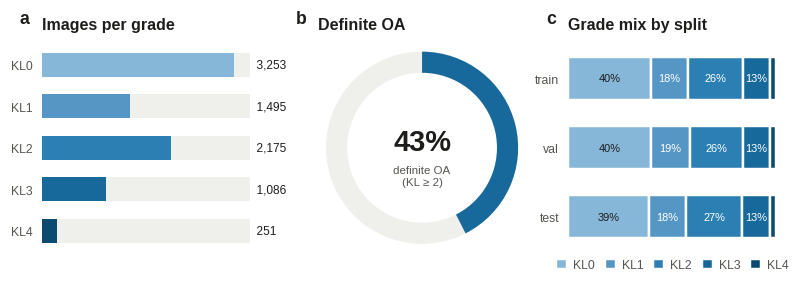

'/content/drive/MyDrive/EvIA_Knee/results/fig_cohort.png'

In [ ]:
KL = [g.split()[0] for g in GRADES]
fig, ax = V.figure(1, 3, width=7.2, height=2.5)
V.track_barh(ax[0], KL, cnt, colors=V.GRADE_RAMP, value_fmt="{:,.0f}")
ax[0].set_title("Images per grade")

oa = float((y >= E.OA_THRESHOLD).mean())
V.donut(ax[1], oa, V.OURS, sub="definite OA\n(KL ≥ 2)")
ax[1].set_title("Definite OA")

# stacked proportions: do the three splits look alike?
props = np.stack([np.bincount(y[idx[s]], minlength=5) / len(idx[s])
                  for s in ("train", "val", "test")])
V.stacked_barh(ax[2], ["train", "val", "test"], props, names=KL)
ax[2].set_title("Grade mix by split")
V.legend(ax[2], loc="upper center", ncol=5, bbox_to_anchor=(0.5, 0.0),
         handlelength=0.9, columnspacing=0.8)
V.panel_letters(ax)
V.save(fig, "fig_cohort", CFG.out_dir)

### 2. Split integrity

Two failure modes to exclude before anything else: leakage between splits, and a split that drifted from the intended stratification.

In [ ]:
# a. no image in two splits
sets = {k: set(ds["paths"][i]) for k, i in idx.items()}
overlap = {f"{a}&{b}": len(sets[a] & sets[b])
           for a, b in [("train","val"), ("train","test"), ("val","test")]}
print("overlapping paths:", overlap)
assert sum(overlap.values()) == 0, "LEAKAGE between splits"

# b. no duplicate filenames anywhere in the cohort
names = [os.path.basename(p) for p in ds["paths"]]
print("duplicate filenames:", len(names) - len(set(names)))

# c. stratification held: is grade independent of split?
obs = np.stack([np.bincount(y[idx[s]], minlength=5) for s in ("train","val","test")])
chi2, p, dof, _ = stats.chi2_contingency(obs)
print(f"\nchi-square grade x split: chi2={chi2:.2f}, dof={dof}, p={p:.3f}")
print("  p > 0.05 -> splits compatible with one distribution (what we want)" if p > .05
      else "  p <= 0.05 -> splits differ; re-check stratification")

print("\nsplit sizes:", {k: len(i) for k, i in idx.items()})

overlapping paths: {'train&val': 0, 'train&test': 0, 'val&test': 0}
duplicate filenames: 0

chi-square grade x split: chi2=1.29, dof=8, p=0.996
  p > 0.05 -> splits compatible with one distribution (what we want)

split sizes: {'train': 5778, 'val': 826, 'test': 1656}


### 3. Image properties

How uniform are the films: size, exposure, focus. Stats use a stratified sample — raise `N_SAMPLE` for more.

In [ ]:
N_SAMPLE = 400                 # per-image decode is slow; 400 is enough for distributions

sample = np.concatenate([
    rng.choice(np.where(y == g)[0], min(N_SAMPLE // 5, int((y == g).sum())), replace=False)
    for g in range(5)])
print(f"sampling {len(sample)} images, stratified by grade")


def image_stats(path):
    # cheap per-image descriptors: geometry, exposure, focus
    img = tf.io.decode_image(tf.io.read_file(path), channels=3,
                             expand_animations=False).numpy()
    H, W = img.shape[:2]
    g = img.mean(-1)
    tissue = g > 10                                    # anything that is not black margin
    frac = float(tissue.mean())

    # drop the black margin, then downsample for speed
    r0, r1 = np.where(tissue.any(1))[0][[0, -1]]
    c0, c1 = np.where(tissue.any(0))[0][[0, -1]]
    small = np.array(tf.image.resize(g[r0:r1+1, c0:c1+1][..., None], (256, 256))[..., 0])

    return dict(h=H, w=W, aspect=W / H, tissue_frac=frac,
                mean_int=float(small.mean()), std_int=float(small.std()),
                lap_var=float(ndi.laplace(small / 255.).var()),    # focus proxy
                frac_dark=float((small < 15).mean()),
                frac_sat=float((small > 245).mean()))


rows = []
for k, i in enumerate(sample):
    r = image_stats(ds["paths"][i]); r["grade"] = int(y[i]); rows.append(r)
    if k % 100 == 0: print(f"  {k}/{len(sample)}")
STAT = pd.DataFrame(rows)
STAT.to_csv(os.path.join(CFG.out_dir, "image_stats.csv"), index=False)

print("\nimage geometry")
print(STAT[["h","w","aspect","tissue_frac"]].describe().round(3).to_string())
print(f"\ndistinct resolutions in sample: {STAT.groupby(['h','w']).ngroups}")
print(STAT.groupby(["h","w"]).size().sort_values(ascending=False).head(5).to_string())

sampling 400 images, stratified by grade
  0/400
  100/400
  200/400
  300/400

image geometry
           h      w  aspect  tissue_frac
count  400.0  400.0   400.0      400.000
mean   224.0  224.0     1.0        0.993
std      0.0    0.0     0.0        0.025
min    224.0  224.0     1.0        0.815
25%    224.0  224.0     1.0        1.000
50%    224.0  224.0     1.0        1.000
75%    224.0  224.0     1.0        1.000
max    224.0  224.0     1.0        1.000

distinct resolutions in sample: 1
h    w  
224  224    400


### 4. Quality, and whether it is confounded with grade

If blur or exposure tracks grade, a model can score well by reading acquisition rather than joint damage. This is the check that catches it.

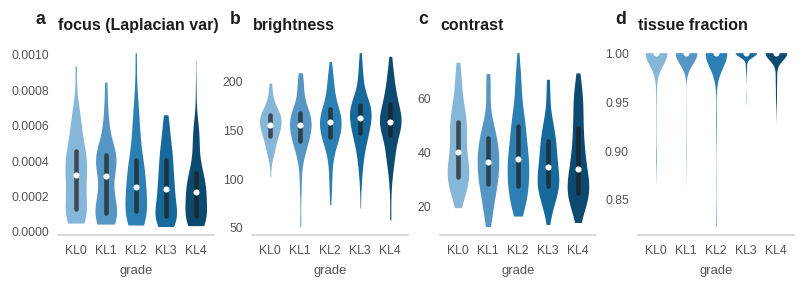

Does quality predict grade?  (|rho| > 0.2 with p < 0.05 is a concern)
  lap_var       rho -0.143  p 0.0041
  mean_int      rho +0.087  p 0.0810
  std_int       rho -0.119  p 0.0172
  tissue_frac   rho +0.036  p 0.4708
  frac_dark     rho -0.052  p 0.3019
  frac_sat      rho +0.053  p 0.2910

flagged low quality: 21/400 (5.2%)
grades among flagged: [1 3 4 4 9]


In [ ]:
fig, ax = V.figure(1, 4, width=7.2, height=2.5)
for a, col, name in zip(ax, ["lap_var","mean_int","std_int","tissue_frac"],
                        ["focus (Laplacian var)","brightness","contrast","tissue fraction"]):
    V.violins(a, [STAT[STAT.grade == g][col].values for g in range(5)],
              names=[f"KL{g}" for g in range(5)])
    a.set(xlabel="grade", title=name)
V.panel_letters(ax)
V.save(fig, "fig_quality", CFG.out_dir)

print("Does quality predict grade?  (|rho| > 0.2 with p < 0.05 is a concern)")
for col in ["lap_var", "mean_int", "std_int", "tissue_frac", "frac_dark", "frac_sat"]:
    rho, p = stats.spearmanr(STAT[col], STAT.grade)
    flag = "   <-- CONFOUND RISK" if abs(rho) > 0.2 and p < .05 else ""
    print(f"  {col:13s} rho {rho:+.3f}  p {p:.4f}{flag}")

# crude unreadable-film flag, the kind a reading service applies
poor = ((STAT.lap_var < STAT.lap_var.quantile(.05))
        | (STAT.frac_dark > .6) | (STAT.frac_sat > .2))
print(f"\nflagged low quality: {poor.sum()}/{len(STAT)} ({poor.mean():.1%})")
print("grades among flagged:", np.bincount(STAT.grade[poor], minlength=5))

### 5. What preprocessing does

One row per grade: raw, border-trimmed, CLAHE. Confirms the pipeline does what the Methods section claims.

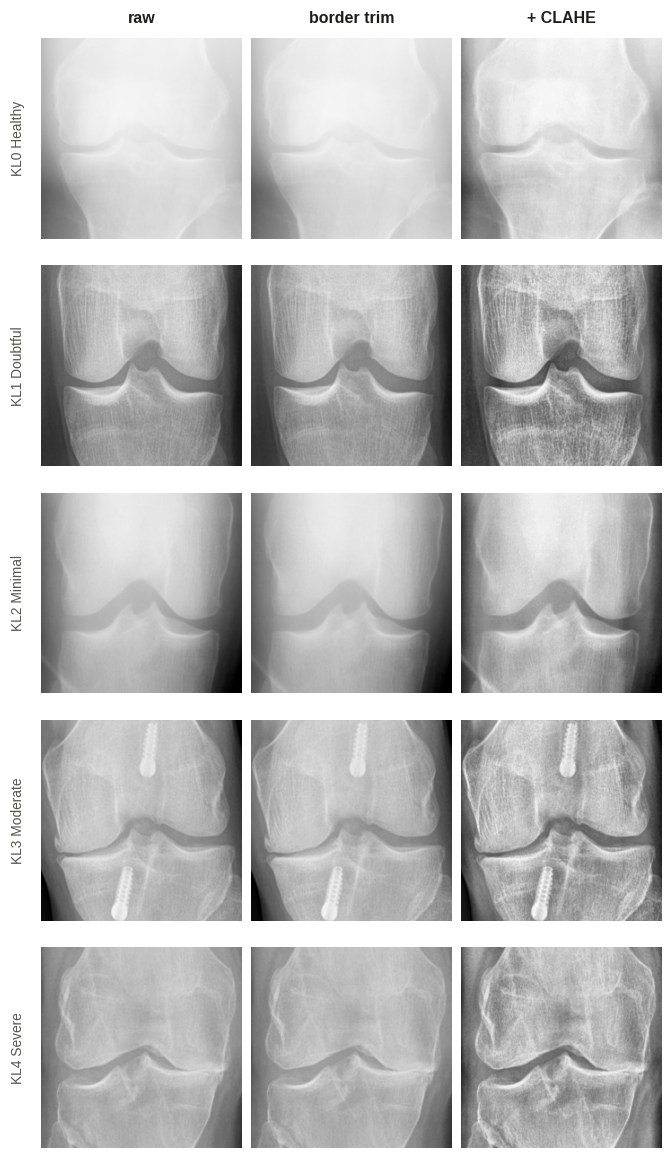

'/content/drive/MyDrive/EvIA_Knee/results/fig_preprocess.png'

In [ ]:
fig, ax = V.figure(5, 3, width=6.0, height=10.5)
for g in range(5):
    i = rng.choice(np.where(y == g)[0])
    raw = tf.io.decode_image(tf.io.read_file(ds["paths"][i]), channels=3,
                             expand_animations=False).numpy()
    crop = E.trim_border(raw)
    enh = E.clahe(crop)
    for a, im, t in zip(ax[g], [raw, crop, enh], ["raw", "border trim", "+ CLAHE"]):
        a.imshow(im); a.axis("off")
        if g == 0: a.set_title(t, loc="center")
    ax[g][0].text(-0.08, .5, GRADES[g], rotation=90, va="center", ha="right",
                  transform=ax[g][0].transAxes, fontsize=9, color=V.INK_2)
V.image_grid_style(ax)
V.save(fig, "fig_preprocess", CFG.out_dir)

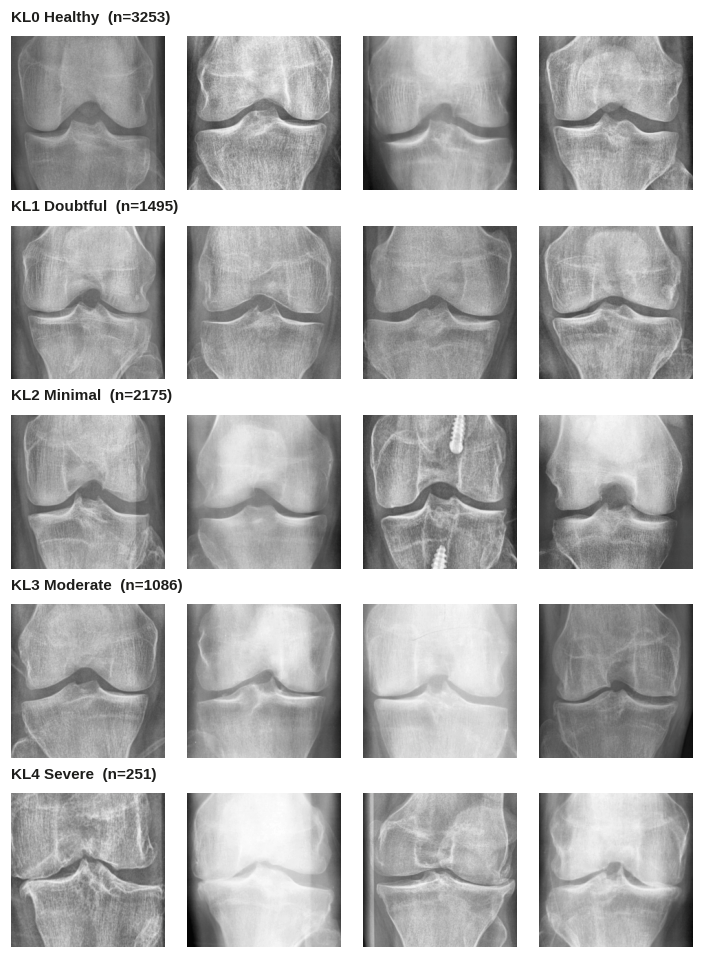

'/content/drive/MyDrive/EvIA_Knee/results/fig_montage.png'

In [ ]:
# montage: four per grade, exactly as the model will see them
fig, ax = V.figure(5, 4, width=6.4, height=8.6)
for g in range(5):
    picks = rng.choice(np.where(y == g)[0], 4, replace=False)
    for a, i in zip(ax[g], picks):
        a.imshow(E.load_one(ds["paths"][i], CFG)); a.axis("off")
    ax[g][0].set_title(f"{GRADES[g]}  (n={int((y==g).sum())})", loc="left", fontsize=10)
V.image_grid_style(ax)
V.save(fig, "fig_montage", CFG.out_dir)

### 6. The contested boundary

KL grading is subjective, and published inter-reader agreement is weakest at KL1 vs KL2 — exactly the call that decides definite OA, and exactly where `u_ref` looks. This section measures how much of the cohort sits there.

In [ ]:
n_bnd = int(np.isin(y, [1, 2]).sum())
print(f"KL1 or KL2 : {n_bnd} images ({n_bnd/len(y):.1%} of the cohort)")
print(f"   KL1 {int((y==1).sum()):5d}")
print(f"   KL2 {int((y==2).sum()):5d}")

# Where do the boundary films sit on the quality measures? If they are also the
# blurriest, a model could separate them on quality rather than on joint space.
bnd = STAT.grade.isin([1, 2])
print("\nquality on the boundary vs elsewhere (sampled):")
for col in ["lap_var", "mean_int", "std_int"]:
    u_, pv = stats.mannwhitneyu(STAT[col][bnd], STAT[col][~bnd])
    print(f"  {col:10s} {STAT[col][bnd].mean():9.3f} vs {STAT[col][~bnd].mean():9.3f}   p={pv:.3g}")

print('''
These are the films a reader is least certain about. If the targeted vacuity works,
the films notebook 04 defers should concentrate here rather than spread evenly
across grades -- that test is section 4 of that notebook.''')

KL1 or KL2 : 3670 images (44.4% of the cohort)
   KL1  1495
   KL2  2175

quality on the boundary vs elsewhere (sampled):
  lap_var        0.000 vs     0.000   p=0.425
  mean_int     154.381 vs   157.569   p=0.273
  std_int       37.973 vs    38.339   p=0.822

These are the films a reader is least certain about. If the targeted vacuity works,
the films notebook 04 defers should concentrate here rather than spread evenly
across grades -- that test is section 4 of that notebook.


### 7. What precision the test set supports

The deferral claim is a sensitivity measured on the OA-positive films in the test set, so its
confidence interval depends on how many of those there are — not on the total.
Worth knowing before the experiment, not after.

In [ ]:
def wilson(k, n, z=1.96):
    # Wilson score interval: correct near 0 or 1, unlike the normal approximation
    if n == 0: return (np.nan, np.nan)
    ph = k / n; d = 1 + z**2 / n
    c = (ph + z**2 / (2*n)) / d
    h = z * math.sqrt(ph*(1-ph)/n + z**2/(4*n*n)) / d
    return (max(0., c - h), min(1., c + h))

n_test = len(idx["test"]); n_ref = int((y[idx["test"]] >= 2).sum())
print(f"test set: {n_test} films, {n_ref} with definite OA\n")

print("95% CI on sensitivity, by true value:")
for sv in (0.80, 0.85, 0.90, 0.95):
    lo, hi = wilson(round(sv * n_ref), n_ref)
    print(f"  sens {sv:.2f} -> [{lo:.3f}, {hi:.3f}]   width {hi-lo:.3f}")

print("\nAt reduced coverage fewer OA-positive films are kept, so the CI widens:")
for cov in (1.0, 0.8, 0.6, 0.4):
    m = int(cov * n_ref)
    lo, hi = wilson(round(0.90 * m), m)
    print(f"  coverage {cov:.0%} -> ~{m} OA films kept, sens 0.90 CI width {hi-lo:.3f}")

print(f"\nCalibration: 15 bins over {n_test} test images = {n_test/15:.0f} per bin on average,")
print("  but confidence is not uniform, so some bins will be near-empty.")
print("  Report ACE (equal-count bins) alongside ECE.")
print(f"\nSeeds: 5 -> detectable |d_z| >= {E.mde(5):.2f};  3 -> {E.mde(3):.2f}  (80% power)")

test set: 1656 films, 721 with definite OA

95% CI on sensitivity, by true value:
  sens 0.80 -> [0.770, 0.828]   width 0.058
  sens 0.85 -> [0.822, 0.874]   width 0.052
  sens 0.90 -> [0.876, 0.920]   width 0.044
  sens 0.95 -> [0.932, 0.964]   width 0.032

At reduced coverage fewer OA-positive films are kept, so the CI widens:
  coverage 100% -> ~721 OA films kept, sens 0.90 CI width 0.044
  coverage 80% -> ~576 OA films kept, sens 0.90 CI width 0.049
  coverage 60% -> ~432 OA films kept, sens 0.90 CI width 0.057
  coverage 40% -> ~288 OA films kept, sens 0.90 CI width 0.070

Calibration: 15 bins over 1656 test images = 110 per bin on average,
  but confidence is not uniform, so some bins will be near-empty.
  Report ACE (equal-count bins) alongside ECE.

Seeds: 5 -> detectable |d_z| >= 1.68;  3 -> 3.26  (80% power)
